# COS802 — 02 GQA Model Baselines (Crop-Suitable Dataset)

This notebook evaluates the **pretrained baseline** on the current filtered GQA validation split.

For each validation question it compares:

- **student view:** full image + question
- **privileged teacher view:** grounded crop + question

Primary metric: **BERTScore-F1**  
Secondary metric: normalized exact match.

## Important revision

This version is safe to use after regenerating Notebook 01:

- computes a fingerprint from the **current validation QA IDs**;
- stores predictions/results under that fingerprint so stale predictions from an older split are never resumed accidentally;
- validates cached QA membership before resuming;
- makes qualitative inspection robust to missing IDs;
- cross-model summary only compares results from the **same current dataset fingerprint**.


## 1 · Dependencies and local paths

In [26]:
%pip -q install -U "transformers>=5.7.0,<6" "accelerate>=1.0" "huggingface_hub>=0.30" "pandas>=2" "Pillow>=10" "tqdm>=4.66" "matplotlib>=3.8" torchvision bert-score


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
from pathlib import Path
import json
import os
import random
import re
import string
import time
import gc

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm


def locate_src_root():
    cwd = Path.cwd().resolve()

    for base in [cwd, *cwd.parents]:
        candidate = base / "src"

        if candidate.is_dir():
            return candidate.resolve()

        if (
            base.name == "src"
            and (base / "data").exists()
        ):
            return base.resolve()

    return (cwd / "src").resolve()


ROOT = locate_src_root()

DATA = ROOT / "data"
PROCESSED = DATA / "processed"
RESULTS = ROOT / "results"

RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

print("src root:", ROOT)


src root: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src


## 2 · Experiment settings

`MAX_EXAMPLES` lets you do a quick local smoke test before evaluating the entire validation split.

Predictions are saved separately for each model and seed.


In [28]:
SEED = 42

MODEL_KEY = "minicpm"
# "smolvlm", "blip", or "minicpm"

MAX_EXAMPLES = None
# e.g. 20 for a smoke test; None = full validation split

SAVE_EVERY = 10

MAX_NEW_TOKENS = 24

# Primary evaluation metric.
BERTSCORE_MODEL = "roberta-large"
BERTSCORE_BATCH_SIZE = 8

MODEL_IDS = {
    "smolvlm": "HuggingFaceTB/SmolVLM-500M-Instruct",
    "blip": "Salesforce/blip-vqa-base",
    "minicpm": "openbmb/MiniCPM-V-4.6",
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    MODEL_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    MODEL_DTYPE = torch.float16
else:
    DEVICE = torch.device("cpu")
    MODEL_DTYPE = torch.float32


print("Model:", MODEL_KEY)
print("Model ID:", MODEL_IDS[MODEL_KEY])
print("Device:", DEVICE)
print("dtype:", MODEL_DTYPE)


Model: minicpm
Model ID: openbmb/MiniCPM-V-4.6
Device: mps
dtype: torch.float16


## 3 · Load and validate the GQA validation set

In [29]:
import hashlib

VAL_CSV = (
    PROCESSED
    / "val.csv"
)

if not VAL_CSV.is_file():
    raise FileNotFoundError(
        f"Missing {VAL_CSV}. Run Notebook 01 first."
    )


val = pd.read_csv(
    VAL_CSV,
    keep_default_na=False,
)


required = {
    "qa_id",
    "image_id",
    "image_path",
    "crop_path",
    "question",
    "answer",
}


missing = (
    required
    - set(val.columns)
)

if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}"
    )


val["qa_id"] = (
    val["qa_id"]
    .astype(str)
)


def file_exists(path):
    return (
        bool(
            str(path).strip()
        )
        and Path(
            str(path)
        ).is_file()
    )


missing_images = (
    ~val.image_path.map(
        file_exists
    )
)

missing_crops = (
    ~val.crop_path.map(
        file_exists
    )
)


if missing_images.any():
    bad = (
        val.loc[
            missing_images,
            [
                "qa_id",
                "image_path",
            ],
        ]
        .head(10)
    )

    display(bad)

    raise FileNotFoundError(
        f"{int(missing_images.sum())} validation full images are missing."
    )


if missing_crops.any():
    bad = (
        val.loc[
            missing_crops,
            [
                "qa_id",
                "crop_path",
            ],
        ]
        .head(10)
    )

    display(bad)

    raise FileNotFoundError(
        f"{int(missing_crops.sum())} validation crops are missing."
    )


# ------------------------------------------------------------
# DATASET FINGERPRINT
# ------------------------------------------------------------
# Sort before hashing so the identifier depends on split membership,
# not dataframe row ordering.
fingerprint_payload = "\n".join(
    sorted(
        val[
            "qa_id"
        ]
        .astype(str)
        .tolist()
    )
)

VAL_FINGERPRINT = (
    hashlib.sha256(
        fingerprint_payload.encode(
            "utf-8"
        )
    )
    .hexdigest()[
        :10
    ]
)


if MAX_EXAMPLES is not None:
    val = (
        val
        .sample(
            n=min(
                MAX_EXAMPLES,
                len(
                    val
                ),
            ),
            random_state=SEED,
        )
        .reset_index(
            drop=True
        )
    )


print(
    "Validation examples:",
    len(val),
)

print(
    "Validation images:",
    val.image_id.nunique(),
)

print(
    "Validation fingerprint:",
    VAL_FINGERPRINT,
)


display(
    val[
        [
            c
            for c in [
                "qa_id",
                "question",
                "answer",
                "structural_type",
                "semantic_type",
                "detailed_type",
                "grounded_object_names",
                "final_crop_area_ratio",
            ]
            if c in val.columns
        ]
    ].head()
)


Validation examples: 753
Validation images: 354
Validation fingerprint: fc5c6fbb23


,qa_id,question,answer,structural_type,semantic_type,detailed_type,grounded_object_names,final_crop_area_ratio
0,111058316,What color is the door?,white,query,attr,directWhich,"[""door""]",0.143099
1,111058304,Are there either white cabinets or doors?,yes,logical,obj,existAttrOr,"[""door""]",0.143099
2,111058270,What toy is it?,stuffed bear,query,cat,category,"[""stuffed bear""]",0.338547
3,3303378,"How does the floor look like, black or beige?",black,choose,attr,chooseAttr,"[""floor""]",0.438438
4,3303293,Are there either blankets or pillows in the pi...,yes,logical,obj,existOr,"[""blanket"", ""pillow""]",0.091946


## 4 · Load one model

The notebook keeps model-specific plumbing isolated here.

For MiniCPM on Apple Silicon we use conservative visual settings (`4x`, one slice) because this model has already shown high unified-memory usage locally.


In [30]:
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText,
    BlipForQuestionAnswering,
    BlipProcessor,
)


def load_model(model_key):
    model_id = MODEL_IDS[
        model_key
    ]

    if model_key == "blip":
        processor = (
            BlipProcessor
            .from_pretrained(
                model_id
            )
        )

        model = (
            BlipForQuestionAnswering
            .from_pretrained(
                model_id,
                dtype=MODEL_DTYPE,
            )
            .to(DEVICE)
        )

    else:
        processor = (
            AutoProcessor
            .from_pretrained(
                model_id
            )
        )

        model = (
            AutoModelForImageTextToText
            .from_pretrained(
                model_id,
                dtype=MODEL_DTYPE,
                low_cpu_mem_usage=True,
            )
            .to(DEVICE)
        )

    model.eval()

    return (
        processor,
        model,
    )


processor, model = load_model(
    MODEL_KEY
)

print(
    "Loaded",
    MODEL_KEY,
    "on",
    next(
        model.parameters()
    ).device,
)


Loading weights: 100%|██████████| 779/779 [00:04<00:00, 165.62it/s]


Loaded minicpm on mps:0


## 5 · Unified VQA inference

In [31]:
def move_batch(
    batch,
    device,
    dtype=None,
):
    moved = {}

    for key, value in batch.items():
        if not torch.is_tensor(
            value
        ):
            moved[key] = value
            continue

        # Only pixel tensors should be explicitly cast.
        if (
            dtype is not None
            and key in {
                "pixel_values",
                "pixel_values_videos",
            }
            and value.is_floating_point()
        ):
            moved[key] = value.to(
                device=device,
                dtype=dtype,
            )
        else:
            moved[key] = value.to(
                device
            )

    return moved


@torch.inference_mode()
def predict_answer(
    image_path,
    question,
):
    with Image.open(
        image_path
    ) as im:
        image = im.convert(
            "RGB"
        )

    if MODEL_KEY == "blip":
        inputs = processor(
            images=image,
            text=question,
            return_tensors="pt",
        )

        inputs = move_batch(
            inputs,
            DEVICE,
            MODEL_DTYPE,
        )

        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        return (
            processor
            .decode(
                generated[0],
                skip_special_tokens=True,
            )
            .strip()
        )

    if MODEL_KEY == "minicpm":
        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": image,
                    },
                    {
                        "type": "text",
                        "text": (
                            question
                            + "\nAnswer briefly with only the answer."
                        ),
                    },
                ],
            }
        ]

        inputs = (
            processor
            .apply_chat_template(
                messages,
                add_generation_prompt=True,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
                enable_thinking=False,
                processor_kwargs={
                    "downsample_mode": "4x",
                    "max_slice_nums": 1,
                },
            )
            .to(DEVICE)
        )

        generated = model.generate(
            **inputs,
            downsample_mode="4x",
            do_sample=False,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        generated = generated[
            :,
            inputs[
                "input_ids"
            ].shape[-1]:
        ]

        return (
            processor
            .batch_decode(
                generated,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=False,
            )[0]
            .strip()
        )

    # SmolVLM / generic image-text-to-text chat model.
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                },
                {
                    "type": "text",
                    "text": (
                        question
                        + "\nAnswer briefly with only the answer."
                    ),
                },
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )

    inputs = move_batch(
        inputs,
        DEVICE,
        MODEL_DTYPE,
    )

    generated = model.generate(
        **inputs,
        do_sample=False,
        max_new_tokens=MAX_NEW_TOKENS,
    )

    generated_trimmed = [
        out_ids[
            len(in_ids):
        ]
        for in_ids, out_ids
        in zip(
            inputs["input_ids"],
            generated,
        )
    ]

    return (
        processor
        .batch_decode(
            generated_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]
        .strip()
    )


## 6 · Single-example smoke test

In [32]:
row = val.iloc[0]

print("Question:", row.question)
print("Ground truth:", row.answer)

full_pred = predict_answer(
    row.image_path,
    row.question,
)

crop_pred = predict_answer(
    row.crop_path,
    row.question,
)

print("Full prediction:", full_pred)
print("Crop prediction:", crop_pred)


Question: What color is the door?
Ground truth: white


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Full prediction: white
Crop prediction: white


## 7 · Paired full-image / privileged-crop inference

The run is resumable. Existing completed QA IDs are skipped.


In [33]:
OUT_DIR = (
    RESULTS
    / MODEL_KEY
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


run_size = (
    "all"
    if MAX_EXAMPLES is None
    else str(
        len(
            val
        )
    )
)


RUN_NAME = (
    f"gqa_val_{run_size}"
    f"_split{VAL_FINGERPRINT}"
    f"_seed{SEED}"
)


PREDICTIONS_PATH = (
    OUT_DIR
    / f"{RUN_NAME}_predictions.csv"
)


current_ids = set(
    val[
        "qa_id"
    ]
    .astype(str)
)


records = []
done = set()


if PREDICTIONS_PATH.exists():

    cached = pd.read_csv(
        PREDICTIONS_PATH,
        keep_default_na=False,
    )

    cached[
        "qa_id"
    ] = (
        cached[
            "qa_id"
        ]
        .astype(str)
    )


    cached_ids = set(
        cached[
            "qa_id"
        ]
    )


    # The fingerprint already makes stale reuse very unlikely.
    # This extra check ensures every cached row still belongs to
    # the current validation split.
    unexpected_ids = (
        cached_ids
        - current_ids
    )


    if unexpected_ids:

        print(
            "Ignoring stale cache because it contains",
            len(
                unexpected_ids
            ),
            "QA IDs not present in the current validation split.",
        )

    else:

        cached = (
            cached[
                cached[
                    "qa_id"
                ].isin(
                    current_ids
                )
            ]
            .copy()
        )

        records = (
            cached
            .to_dict(
                "records"
            )
        )

        done = set(
            cached[
                "qa_id"
            ]
        )

        print(
            "Resuming current split:",
            len(
                done
            ),
            "already complete",
        )


for row in tqdm(
    val.itertuples(
        index=False
    ),
    total=len(
        val
    ),
    desc=(
        f"{MODEL_KEY}: full + crop"
    ),
):

    qa_id = str(
        row.qa_id
    )

    if qa_id in done:
        continue


    rec = {
        "qa_id":
            qa_id,

        "image_id":
            str(
                row.image_id
            ),

        "question":
            row.question,

        "answer":
            row.answer,

        "full_pred":
            "",

        "crop_pred":
            "",

        "full_error":
            "",

        "crop_error":
            "",

        "val_fingerprint":
            VAL_FINGERPRINT,
    }


    try:

        rec[
            "full_pred"
        ] = predict_answer(
            row.image_path,
            row.question,
        )

    except Exception as exc:

        rec[
            "full_error"
        ] = (
            f"{type(exc).__name__}: "
            f"{str(exc)[:500]}"
        )


    try:

        rec[
            "crop_pred"
        ] = predict_answer(
            row.crop_path,
            row.question,
        )

    except Exception as exc:

        rec[
            "crop_error"
        ] = (
            f"{type(exc).__name__}: "
            f"{str(exc)[:500]}"
        )


    records.append(
        rec
    )

    done.add(
        qa_id
    )


    if (
        len(
            records
        )
        % SAVE_EVERY
        == 0
    ):

        pd.DataFrame(
            records
        ).to_csv(
            PREDICTIONS_PATH,
            index=False,
        )


    if DEVICE.type == "mps":

        torch.mps.empty_cache()


predictions = pd.DataFrame(
    records
)


# Keep only rows from the current split and put them in the same
# order as the current validation dataframe.
predictions = (
    predictions[
        predictions[
            "qa_id"
        ]
        .astype(str)
        .isin(
            current_ids
        )
    ]
    .copy()
)


order = {
    str(
        qa_id
    ):
        idx

    for idx, qa_id
    in enumerate(
        val[
            "qa_id"
        ]
    )
}


predictions[
    "_order"
] = (
    predictions[
        "qa_id"
    ]
    .astype(str)
    .map(
        order
    )
)


predictions = (
    predictions
    .sort_values(
        "_order"
    )
    .drop(
        columns=[
            "_order"
        ]
    )
    .reset_index(
        drop=True
    )
)


predictions.to_csv(
    PREDICTIONS_PATH,
    index=False,
)


print(
    "Saved:",
    PREDICTIONS_PATH,
)

print(
    "Prediction rows:",
    len(
        predictions
    ),
)


minicpm: full + crop: 100%|██████████| 753/753 [22:15<00:00,  1.77s/it]

Saved: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/minicpm/gqa_val_all_splitfc5c6fbb23_seed42_predictions.csv
Prediction rows: 753


## 8 · Normalized exact match and teacher diagnostics

Four paired cases:

- `teacher_can_help`: full-image model wrong, crop teacher correct
- `teacher_hurts`: full-image model correct, crop teacher wrong
- `both_correct`
- `both_wrong`

These categories are now diagnostics of model behaviour on **GQA-grounded evidence**, rather than being used to construct the dataset.


### Primary metric: BERTScore-F1

The baseline comparison now uses **mean BERTScore-F1 as the primary metric** for both the full-image student view and privileged crop view. The main `teacher_advantage` is therefore:

\[
\Delta_{\mathrm{teacher}} =
F1_{\mathrm{BERTScore,crop}} -
F1_{\mathrm{BERTScore,full}}
\]

Normalized exact match is retained as a **secondary metric** and is still used for the discrete `teacher_can_help`, `teacher_hurts`, `both_correct`, and `both_wrong` diagnostic categories.


In [34]:
from bert_score import score as bertscore_score


ARTICLES = re.compile(
    r"\b(a|an|the)\b"
)

PUNCT = str.maketrans(
    "",
    "",
    string.punctuation,
)


def normalize_answer(x):
    text = (
        str(x)
        .lower()
        .translate(PUNCT)
    )

    text = ARTICLES.sub(
        " ",
        text,
    )

    return " ".join(
        text.split()
    )


# ============================================================
# KEEP ONLY SUCCESSFUL FULL + CROP PREDICTIONS
# ============================================================

success = predictions[
    predictions.full_error.eq("")
    & predictions.crop_error.eq("")
    & predictions.full_pred.astype(str).str.strip().ne("")
    & predictions.crop_pred.astype(str).str.strip().ne("")
].copy().reset_index(drop=True)


if len(success) == 0:
    raise RuntimeError(
        "No successful paired full-image/crop predictions were available."
    )


# ============================================================
# SECONDARY METRIC: NORMALIZED EXACT MATCH
# ============================================================

success[
    "full_correct"
] = (
    success.full_pred
    .map(
        normalize_answer
    )
    .eq(
        success.answer.map(
            normalize_answer
        )
    )
)


success[
    "crop_correct"
] = (
    success.crop_pred
    .map(
        normalize_answer
    )
    .eq(
        success.answer.map(
            normalize_answer
        )
    )
)


# Keep the original binary diagnostic cases.
success[
    "case"
] = np.select(
    [
        (
            success.full_correct
            & success.crop_correct
        ),
        (
            ~success.full_correct
            & success.crop_correct
        ),
        (
            success.full_correct
            & ~success.crop_correct
        ),
    ],
    [
        "both_correct",
        "teacher_can_help",
        "teacher_hurts",
    ],
    default="both_wrong",
)


full_exact_match = float(
    success.full_correct.mean()
)

crop_exact_match = float(
    success.crop_correct.mean()
)

exact_match_teacher_advantage = (
    crop_exact_match
    - full_exact_match
)


# ============================================================
# FREE VLM MEMORY BEFORE BERTSCORE
# ============================================================

try:
    del model
except NameError:
    pass

try:
    del processor
except NameError:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

elif torch.backends.mps.is_available():
    try:
        torch.mps.empty_cache()
    except Exception:
        pass


# ============================================================
# PRIMARY METRIC: BERTSCORE-F1
# ============================================================

BERTSCORE_DEVICE = str(
    DEVICE
)


print(
    f"Computing BERTScore with "
    f"{BERTSCORE_MODEL} on {BERTSCORE_DEVICE}..."
)


full_p, full_r, full_f1 = bertscore_score(
    success[
        "full_pred"
    ].astype(str).tolist(),
    success[
        "answer"
    ].astype(str).tolist(),
    model_type=BERTSCORE_MODEL,
    lang="en",
    device=BERTSCORE_DEVICE,
    batch_size=BERTSCORE_BATCH_SIZE,
    verbose=True,
)


crop_p, crop_r, crop_f1 = bertscore_score(
    success[
        "crop_pred"
    ].astype(str).tolist(),
    success[
        "answer"
    ].astype(str).tolist(),
    model_type=BERTSCORE_MODEL,
    lang="en",
    device=BERTSCORE_DEVICE,
    batch_size=BERTSCORE_BATCH_SIZE,
    verbose=True,
)


success[
    "full_bertscore_precision"
] = full_p.cpu().numpy()

success[
    "full_bertscore_recall"
] = full_r.cpu().numpy()

success[
    "full_bertscore_f1"
] = full_f1.cpu().numpy()


success[
    "crop_bertscore_precision"
] = crop_p.cpu().numpy()

success[
    "crop_bertscore_recall"
] = crop_r.cpu().numpy()

success[
    "crop_bertscore_f1"
] = crop_f1.cpu().numpy()


# Per-example semantic advantage of the privileged crop.
success[
    "bertscore_f1_delta"
] = (
    success[
        "crop_bertscore_f1"
    ]
    - success[
        "full_bertscore_f1"
    ]
)


full_bertscore_f1 = float(
    success[
        "full_bertscore_f1"
    ].mean()
)

crop_bertscore_f1 = float(
    success[
        "crop_bertscore_f1"
    ].mean()
)

teacher_advantage = (
    crop_bertscore_f1
    - full_bertscore_f1
)


# ============================================================
# SAVE METRICS
# ============================================================

metrics = {
    "dataset": "GQA",
    "model_key": MODEL_KEY,
    "model_id": MODEL_IDS[
        MODEL_KEY
    ],
    "seed": SEED,
    "val_fingerprint": VAL_FINGERPRINT,
    "n_validation_rows": int(
        len(
            val
        )
    ),
    "n_evaluated": int(
        len(success)
    ),

    # Primary metric
    "primary_metric": "BERTScore-F1",
    "bertscore_model": BERTSCORE_MODEL,
    "full_bertscore_f1": full_bertscore_f1,
    "crop_bertscore_f1": crop_bertscore_f1,
    "teacher_advantage": teacher_advantage,

    # Secondary metric
    "full_exact_match": full_exact_match,
    "crop_exact_match": crop_exact_match,
    "exact_match_teacher_advantage": exact_match_teacher_advantage,

    # Existing exact-match-based diagnostics
    "potentially_distillable_fraction": float(
        success.case.eq(
            "teacher_can_help"
        ).mean()
    ),
    "teacher_hurts_fraction": float(
        success.case.eq(
            "teacher_hurts"
        ).mean()
    ),
    "case_counts": {
        str(k): int(v)
        for k, v
        in success.case
        .value_counts()
        .to_dict()
        .items()
    },
}


METRICS_PATH = (
    OUT_DIR
    / f"{RUN_NAME}_metrics.json"
)


with open(
    METRICS_PATH,
    "w",
) as f:
    json.dump(
        metrics,
        f,
        indent=2,
    )


DIAGNOSTICS_PATH = (
    OUT_DIR
    / f"{RUN_NAME}_diagnostics.csv"
)


success.to_csv(
    DIAGNOSTICS_PATH,
    index=False,
)


print(
    json.dumps(
        metrics,
        indent=2,
    )
)

print(
    "\\nSaved diagnostics:",
    DIAGNOSTICS_PATH,
)


Computing BERTScore with roberta-large on mps...


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 9264.36it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


100%|██████████| 26/26 [00:00<00:00, 33.92it/s]


computing greedy matching.


...

calculating scores...
computing bert embedding.


100%|██████████| 27/27 [00:00<00:00, 39.76it/s]


computing greedy matching.


100%|██████████| 95/95 [00:00<00:00, 137.07it/s]

done in 1.37 seconds, 547.89 sentences/sec
{
  "dataset": "GQA",
  "model_key": "minicpm",
  "model_id": "openbmb/MiniCPM-V-4.6",
  "seed": 42,
  "val_fingerprint": "fc5c6fbb23",
  "n_validation_rows": 753,
  "n_evaluated": 753,
  "primary_metric": "BERTScore-F1",
  "bertscore_model": "roberta-large",
  "full_bertscore_f1": 0.9743274450302124,
  "crop_bertscore_f1": 0.9740627408027649,
  "teacher_advantage": -0.00026470422744750977,
  "full_exact_match": 0.7410358565737052,
  "crop_exact_match": 0.7450199203187251,
  "exact_match_teacher_advantage": 0.003984063745019917,
  "potentially_distillable_fraction": 0.055776892430278883,
  "teacher_hurts_fraction": 0.05179282868525897,
  "case_counts": {
    "both_correct": 519,
    "both_wrong": 153,
    "teacher_can_help": 42,
    "teacher_hurts": 39
  }
}
\nSaved diagnostics: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/minicpm/gqa_val_all_splitfc5c6fbb23_seed42_diagnostics.csv


## 9 · Diagnostic distribution

The important sanity check is not that `teacher_hurts` disappears entirely—it should not—but that the **average crop-teacher accuracy is meaningfully above full-image accuracy** and that the crop-error cases are no longer dominated by obviously incorrect privileged regions.


In [35]:
case_summary = (
    success.case
    .value_counts()
    .reindex(
        [
            "teacher_can_help",
            "both_correct",
            "teacher_hurts",
            "both_wrong",
        ],
        fill_value=0,
    )
    .rename_axis(
        "case"
    )
    .reset_index(
        name="count"
    )
)


case_summary[
    "fraction"
] = (
    case_summary[
        "count"
    ]
    / len(success)
)


display(
    case_summary
)


,case,count,fraction
0,teacher_can_help,42,0.055777
1,both_correct,519,0.689243
2,teacher_hurts,39,0.051793
3,both_wrong,153,0.203187


## 10 · Qualitative inspection of help/hurt cases


 teacher_can_help n= 42


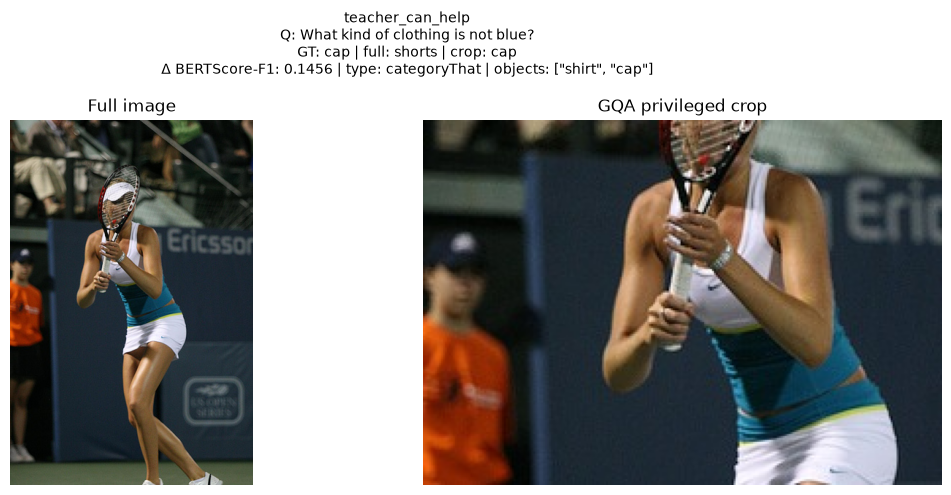

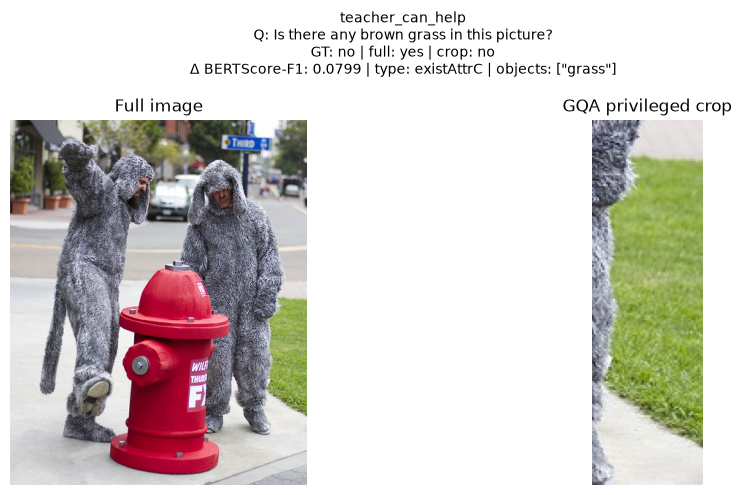

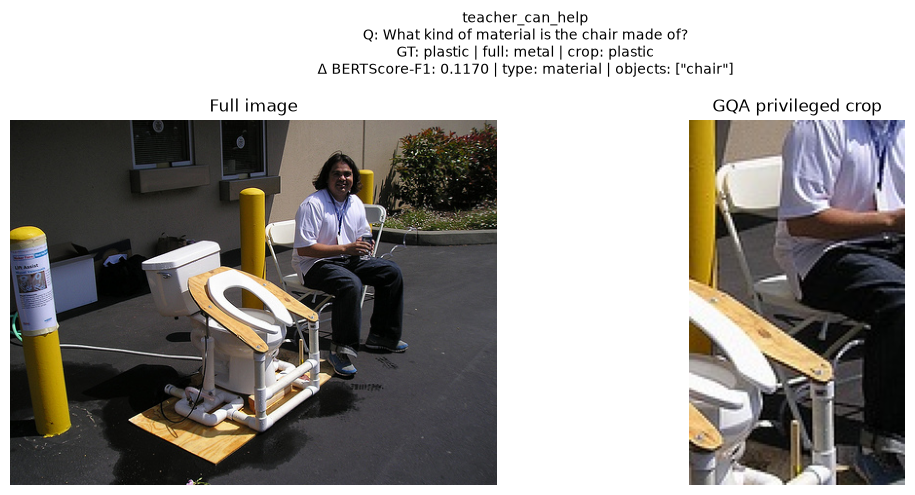

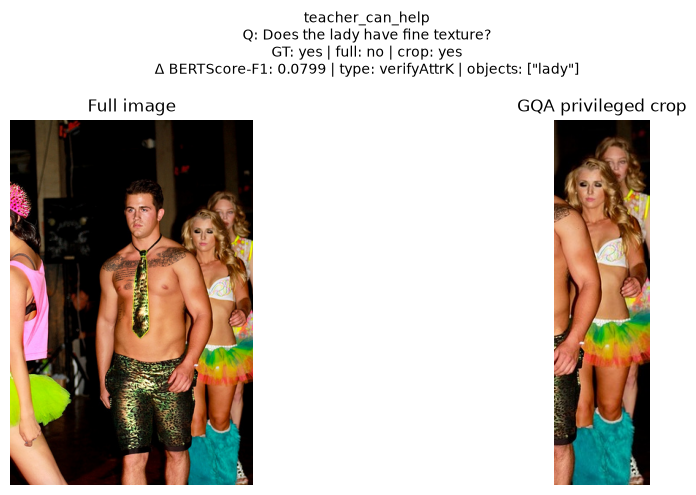

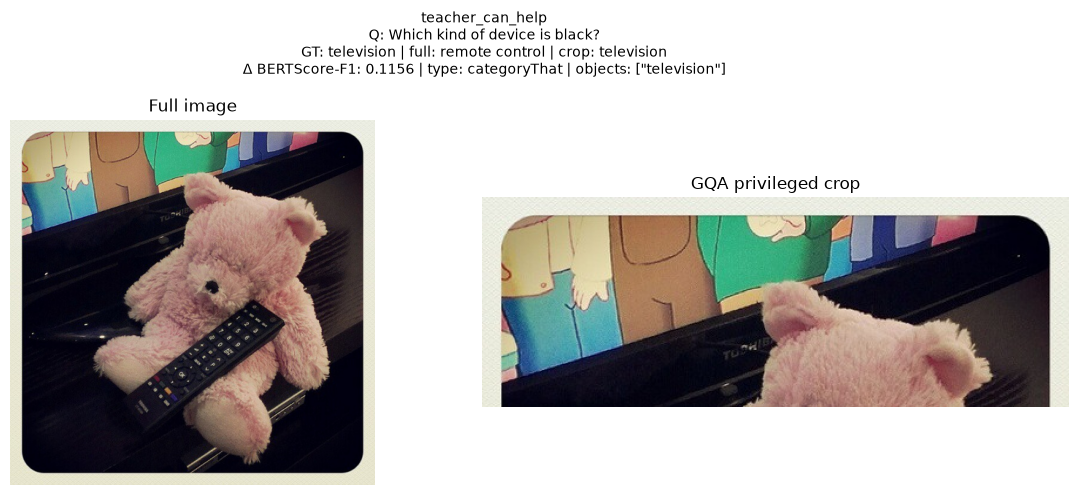


 teacher_hurts n= 39


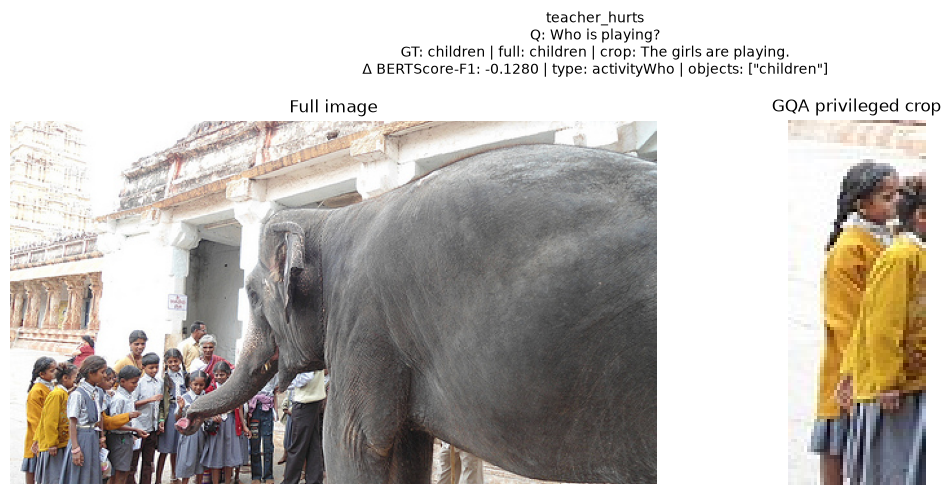

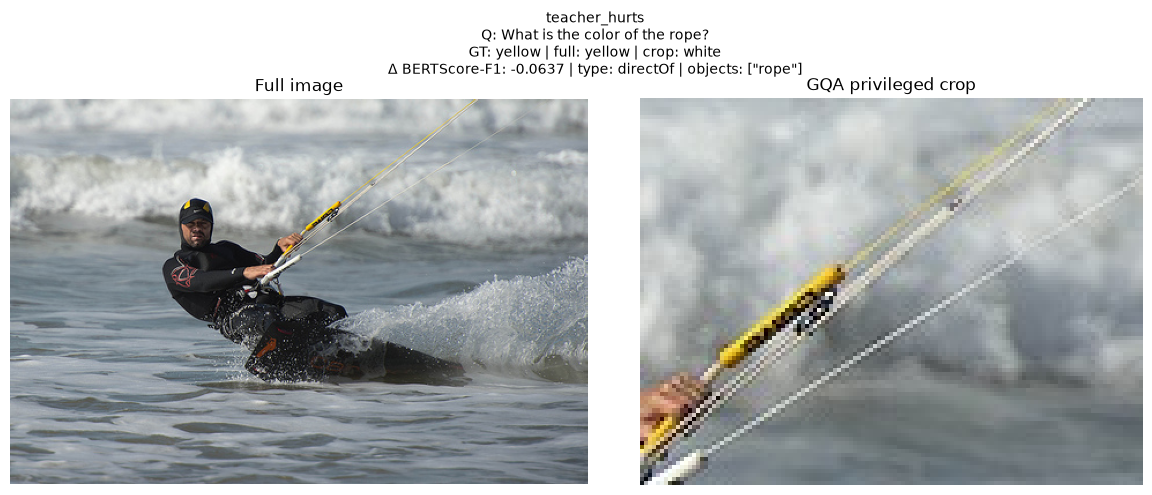

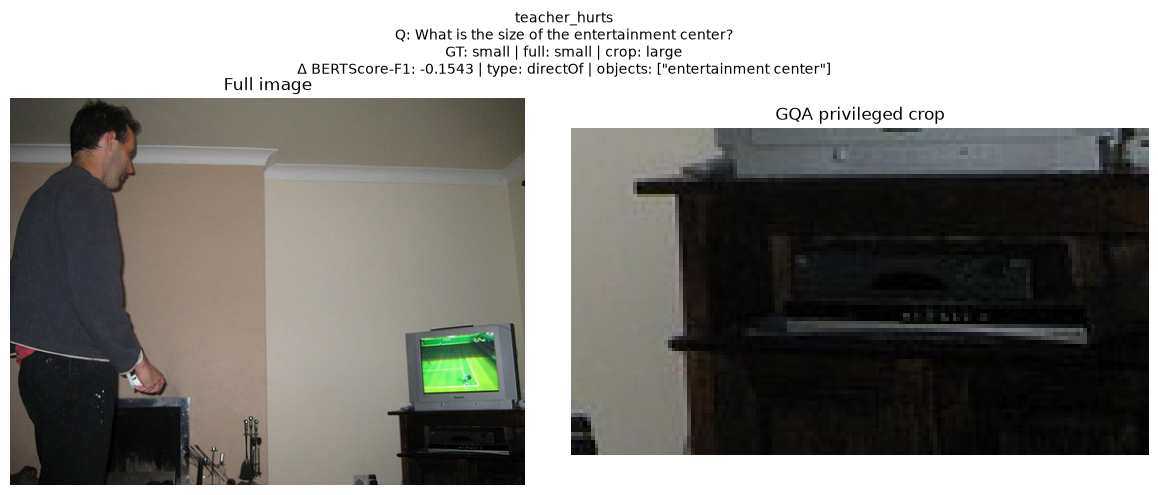

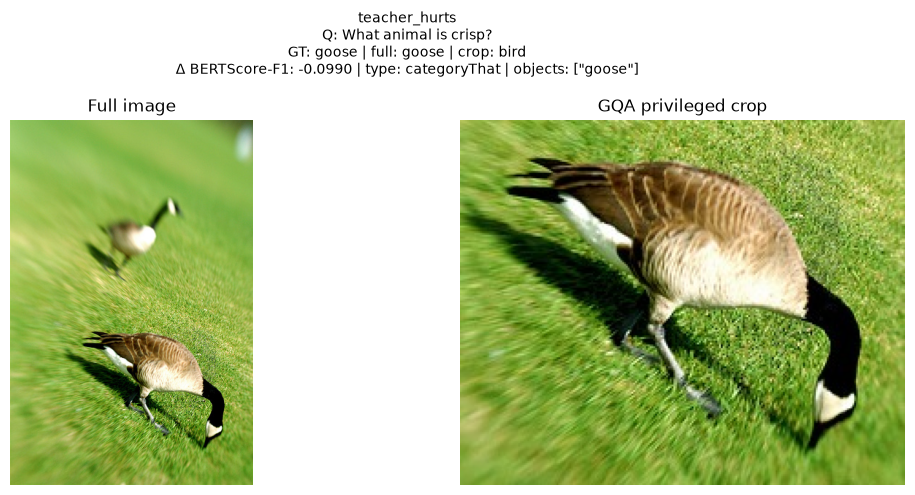

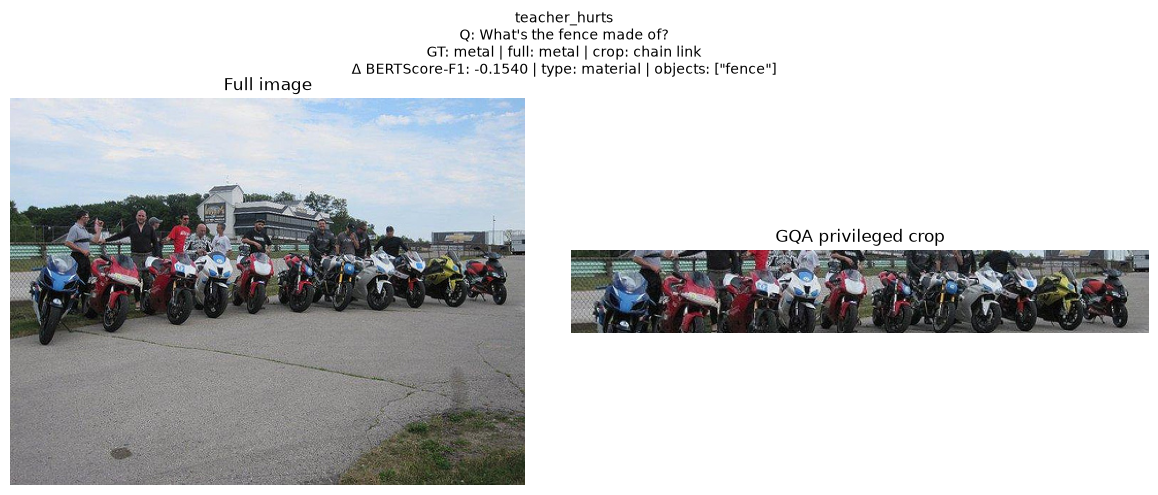


 both_wrong n= 153


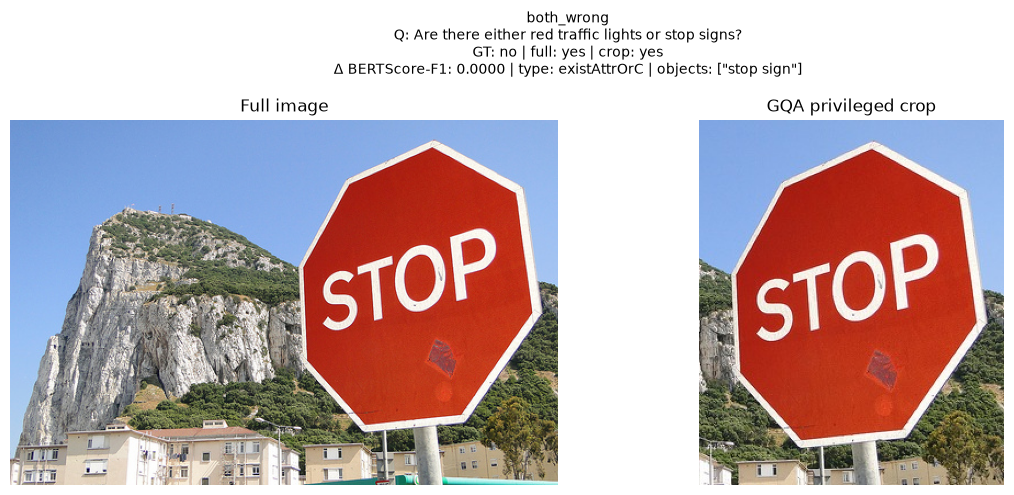

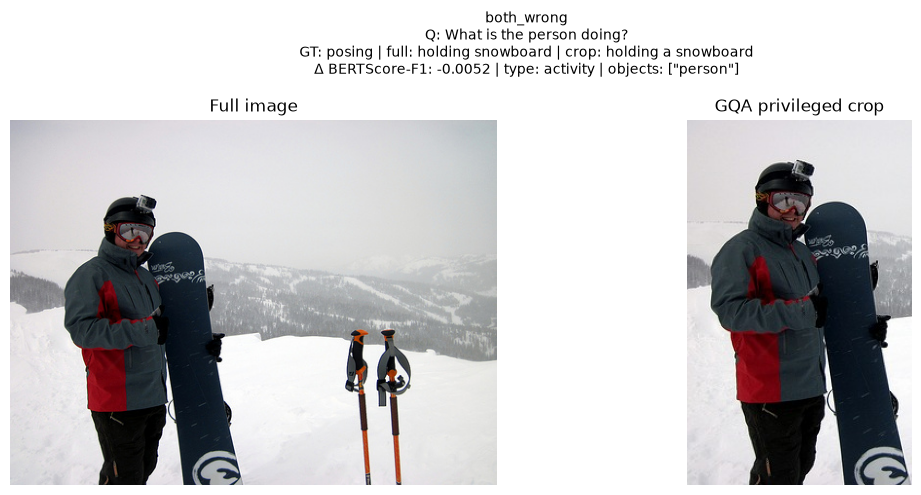

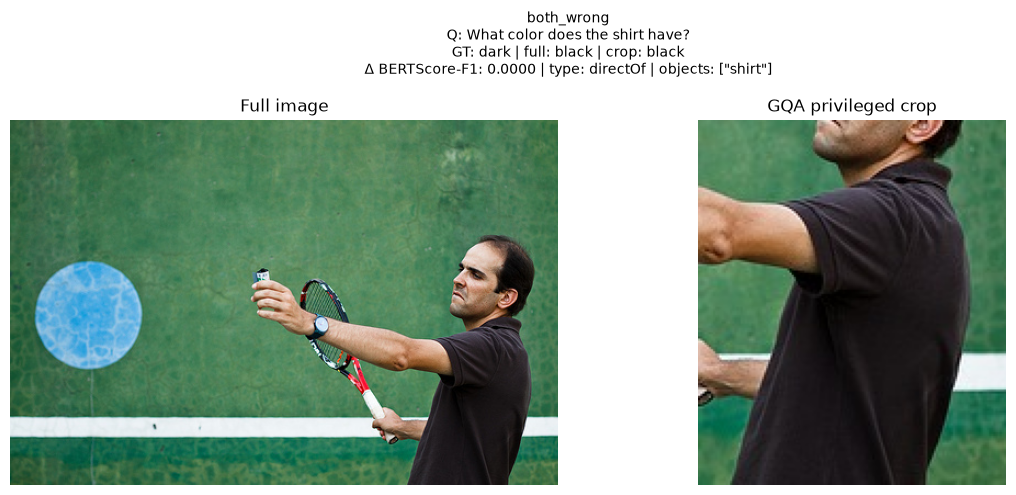

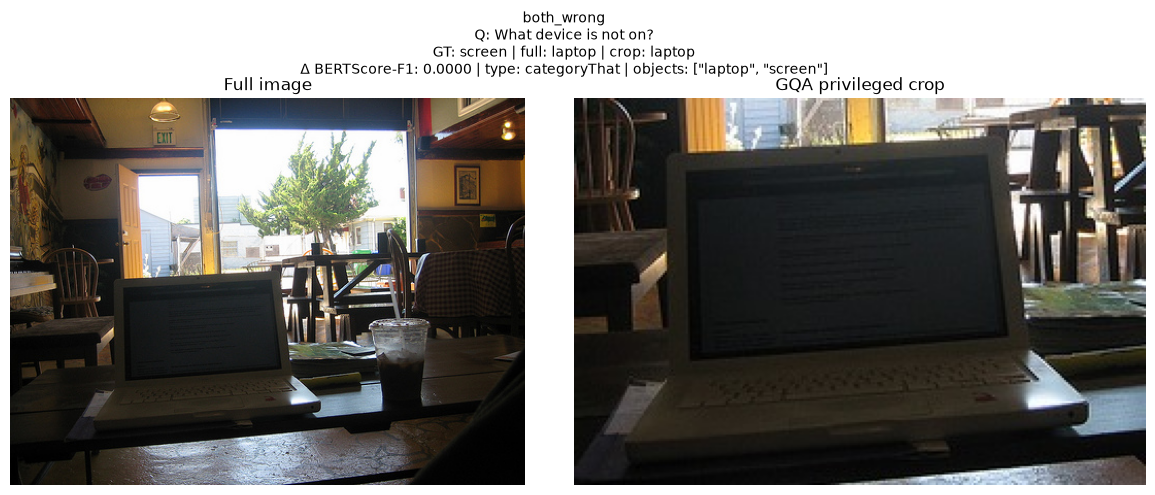

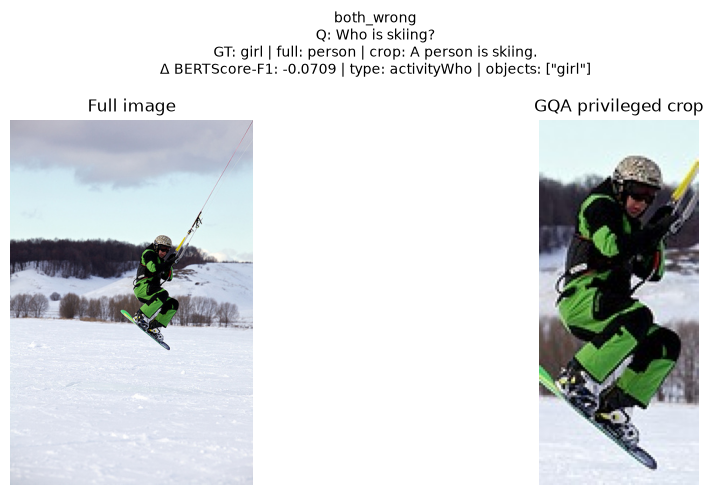

In [36]:
from IPython.display import display
import matplotlib.pyplot as plt


# Fast lookup from the CURRENT validation split only.
val_lookup = (
    val
    .assign(
        qa_id=lambda df:
            df[
                "qa_id"
            ].astype(str)
    )
    .set_index(
        "qa_id",
        drop=False,
    )
)


def show_case(
    row,
):

    qa_id = str(
        row.qa_id
    )


    if qa_id not in val_lookup.index:

        print(
            f"Skipping QA {qa_id}: "
            "not present in the current validation split."
        )

        return


    source = (
        val_lookup
        .loc[
            qa_id
        ]
    )


    # Defensive handling if duplicated IDs ever appear.
    if isinstance(
        source,
        pd.DataFrame,
    ):
        source = (
            source
            .iloc[
                0
            ]
        )


    with Image.open(
        source.image_path
    ) as img:

        full = (
            img.convert(
                "RGB"
            )
            .copy()
        )


    with Image.open(
        source.crop_path
    ) as img:

        crop = (
            img.convert(
                "RGB"
            )
            .copy()
        )


    fig, axes = plt.subplots(
        1,
        2,
        figsize=(
            12,
            5,
        ),
    )


    axes[
        0
    ].imshow(
        full
    )

    axes[
        0
    ].set_title(
        "Full image"
    )

    axes[
        0
    ].axis(
        "off"
    )


    axes[
        1
    ].imshow(
        crop
    )

    axes[
        1
    ].set_title(
        "GQA privileged crop"
    )

    axes[
        1
    ].axis(
        "off"
    )


    objects = (
        source.get(
            "grounded_object_names",
            "",
        )
    )


    detailed_type = (
        source.get(
            "detailed_type",
            "",
        )
    )


    delta = (
        getattr(
            row,
            "bertscore_f1_delta",
            float(
                "nan"
            ),
        )
    )


    fig.suptitle(
        f"{row.case}\n"
        f"Q: {row.question}\n"
        f"GT: {row.answer} | "
        f"full: {row.full_pred} | "
        f"crop: {row.crop_pred}\n"
        f"Δ BERTScore-F1: {delta:.4f} | "
        f"type: {detailed_type} | "
        f"objects: {objects}",
        fontsize=10,
    )


    plt.tight_layout()
    plt.show()


# success was created from current predictions, but filter again
# defensively so qualitative inspection can never use stale IDs.
success_current = (
    success[
        success[
            "qa_id"
        ]
        .astype(str)
        .isin(
            set(
                val_lookup.index
            )
        )
    ]
    .copy()
)


for category in [
    "teacher_can_help",
    "teacher_hurts",
    "both_wrong",
]:

    pool = (
        success_current[
            success_current.case.eq(
                category
            )
        ]
    )


    print(
        "\n",
        category,
        "n=",
        len(
            pool
        ),
    )


    if len(
        pool
    ) == 0:

        continue


    sample = (
        pool
        .sample(
            n=min(
                5,
                len(
                    pool
                ),
            ),
            random_state=SEED,
        )
    )


    for row in sample.itertuples(
        index=False
    ):

        show_case(
            row
        )


## 11 · Cross-model summary

After running this notebook once for each model, this cell gathers whatever completed metrics files exist.


In [37]:
summaries = []


for key in MODEL_IDS:

    model_dir = (
        RESULTS
        / key
    )


    if not model_dir.is_dir():
        continue


    metric_files = sorted(
        model_dir.glob(
            (
                f"gqa_val_*"
                f"_split{VAL_FINGERPRINT}"
                f"_seed{SEED}"
                f"_metrics.json"
            )
        )
    )


    if not metric_files:
        continue


    fp = (
        metric_files[
            -1
        ]
    )


    with open(
        fp,
        "r",
    ) as f:

        item = json.load(
            f
        )


    if (
        item.get(
            "val_fingerprint"
        )
        != VAL_FINGERPRINT
    ):
        continue


    summaries.append(
        item
    )


if summaries:

    summary_df = (
        pd.DataFrame(
            summaries
        )
    )


    columns = [
        c

        for c in [
            "model_key",
            "n_validation_rows",
            "n_evaluated",
            "full_bertscore_f1",
            "crop_bertscore_f1",
            "teacher_advantage",
            "full_exact_match",
            "crop_exact_match",
            "exact_match_teacher_advantage",
            "potentially_distillable_fraction",
            "teacher_hurts_fraction",
        ]

        if c in summary_df.columns
    ]


    display(
        summary_df[
            columns
        ]
    )


else:

    print(
        "No completed baseline metrics found "
        "for the CURRENT validation split yet."
    )

    print(
        "Current validation fingerprint:",
        VAL_FINGERPRINT,
    )


,model_key,n_validation_rows,n_evaluated,full_bertscore_f1,crop_bertscore_f1,teacher_advantage,full_exact_match,crop_exact_match,exact_match_teacher_advantage,potentially_distillable_fraction,teacher_hurts_fraction
0,smolvlm,753,753,0.925747,0.925077,-0.000670,0.556441,0.567065,0.010624,0.111554,0.100930
1,blip,753,753,0.956848,0.958733,0.001884,0.581673,0.602922,0.021248,0.077025,0.055777
2,minicpm,753,753,0.974327,0.974063,-0.000265,0.741036,0.745020,0.003984,0.055777,0.051793


## 12 · Handoff

For the revised crop-suitable dataset:

1. run this notebook separately for `smolvlm`, `blip`, and `minicpm`;
2. confirm the crop view now has a meaningful positive BERTScore-F1 / exact-match advantage over the full-image view;
3. inspect `teacher_hurts` cases qualitatively;
4. only then rerun SFT and OPSD on the same filtered train/validation/test split.

All outputs are tagged with the current validation-set fingerprint, so results from an older Notebook 01 split are not mixed into this experiment.
